In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, cohen_kappa_score,
    matthews_corrcoef, confusion_matrix, roc_curve, precision_recall_curve,
    brier_score_loss, classification_report
)
from sklearn.calibration import calibration_curve

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'
print("Evaluation libraries successfully loaded.")

Evaluation libraries successfully loaded.


In [2]:
csv_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(csv_path):
    csv_path = os.path.join("26-10-2026", "Task 2", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(csv_path)
print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")

num_features = [
    'Age', 'Rating', 'Positive Feedback Count', 'Review_Length',
    'Review_Word_Count', 'Exclamation_Count', 'Sentiment_Compound',
    'Sentiment_Pos', 'Sentiment_Neg', 'Positive_Word_Count',
    'Negative_Word_Count', 'Fit_Issue_Word_Count', 'Rating_x_Sentiment'
]
cat_features = ['Department Name', 'Division Name']
target = 'Recommended IND'

X = df[num_features + cat_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

rf_model = RandomForestClassifier(
    n_estimators=250, max_depth=8, min_samples_split=2, min_samples_leaf=2,
    max_features=0.5, random_state=42, n_jobs=-1
)
rf_model.fit(X_train_trans, y_train)

lr_model = LogisticRegression(
    C=49.29, penalty='l2', solver='saga', class_weight='balanced',
    max_iter=1000, random_state=42
)
lr_model.fit(X_train_trans, y_train)

print("Models trained and ready for diagnostic evaluation.")

Loaded dataset: 23486 rows, 23 columns


C:\Users\panch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Models trained and ready for diagnostic evaluation.


In [3]:
y_pred_naive = np.ones_like(y_test)
y_prob_naive = np.full_like(y_test, fill_value=np.mean(y_train), dtype=float)

models_eval = {
    'Naive Majority Predictor': (y_pred_naive, y_prob_naive),
    'Logistic Regression (Balanced)': (lr_model.predict(X_test_trans), lr_model.predict_proba(X_test_trans)[:, 1]),
    'Random Forest Classifier': (rf_model.predict(X_test_trans), rf_model.predict_proba(X_test_trans)[:, 1])
}

metrics_records = []
for name, (pred, prob) in models_eval.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    
    acc = accuracy_score(y_test, pred)
    bal_acc = ( (tp / (tp + fn)) + (tn / (tn + fp)) ) / 2.0
    prec_1 = precision_score(y_test, pred, pos_label=1, zero_division=0)
    rec_1 = recall_score(y_test, pred, pos_label=1, zero_division=0)
    f1_1 = f1_score(y_test, pred, pos_label=1, zero_division=0)
    
    prec_0 = precision_score(y_test, pred, pos_label=0, zero_division=0)
    rec_0 = recall_score(y_test, pred, pos_label=0, zero_division=0)
    f1_0 = f1_score(y_test, pred, pos_label=0, zero_division=0)
    
    macro_f1 = f1_score(y_test, pred, average='macro')
    kappa = cohen_kappa_score(y_test, pred)
    mcc = matthews_corrcoef(y_test, pred)
    
    if len(np.unique(prob)) > 1:
        roc_auc = roc_auc_score(y_test, prob)
        pr_auc = average_precision_score(y_test, prob)
        brier = brier_score_loss(y_test, prob)
    else:
        roc_auc = 0.50
        pr_auc = np.mean(y_test)
        brier = brier_score_loss(y_test, prob)
        
    metrics_records.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Balanced_Accuracy': round(bal_acc, 4),
        'Precision_Class1': round(prec_1, 4),
        'Recall_Class1': round(rec_1, 4),
        'F1_Class1': round(f1_1, 4),
        'Precision_Class0': round(prec_0, 4),
        'Recall_Class0': round(rec_0, 4),
        'F1_Class0': round(f1_0, 4),
        'Macro_F1': round(macro_f1, 4),
        'Cohen_Kappa': round(kappa, 4),
        'MCC': round(mcc, 4),
        'ROC_AUC': round(roc_auc, 4),
        'PR_AUC': round(pr_auc, 4),
        'Brier_Score': round(brier, 4)
    })

df_metrics = pd.DataFrame(metrics_records)
df_metrics.to_csv("classification_metrics_comprehensive_benchmark.csv", index=False)
df_metrics

,Model,Accuracy,Balanced_Accuracy,Precision_Class1,Recall_Class1,F1_Class1,Precision_Class0,Recall_Class0,F1_Class0,Macro_F1,Cohen_Kappa,MCC,ROC_AUC,PR_AUC,Brier_Score
0,Naive Majority Predictor,0.8223,0.5000,0.8223,1.0000,0.9025,0.0000,0.0000,0.0000,0.4512,0.0000,0.0000,0.5000,0.8223,0.1461
1,Logistic Regression (Balanced),0.9355,0.9401,0.9879,0.9330,0.9597,0.7533,0.9473,0.8393,0.8995,0.7996,0.8078,0.9779,0.9948,0.0516
2,Random Forest Classifier,0.9413,0.9056,0.9674,0.9609,0.9642,0.8246,0.8503,0.8373,0.9007,0.8014,0.8016,0.9753,0.9939,0.0421


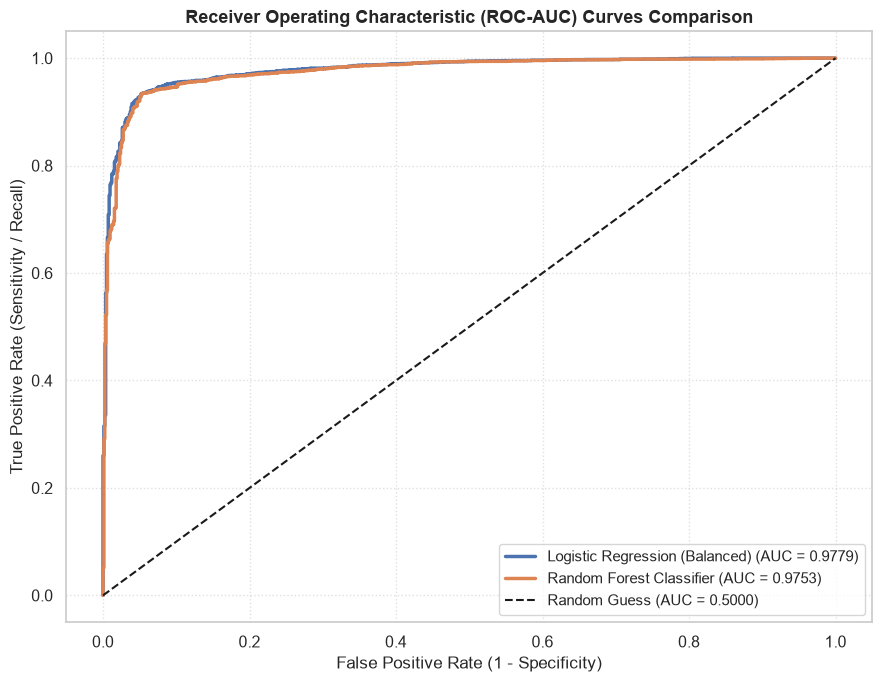

In [4]:
plt.figure(figsize=(9, 7))
for name, (_, prob) in models_eval.items():
    if len(np.unique(prob)) > 1:
        fpr, tpr, _ = roc_curve(y_test, prob)
        auc_val = roc_auc_score(y_test, prob)
        plt.plot(fpr, tpr, linewidth=2.5, label=f"{name} (AUC = {auc_val:.4f})")
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label="Random Guess (AUC = 0.5000)")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
plt.title("Receiver Operating Characteristic (ROC-AUC) Curves Comparison", fontweight='bold', fontsize=13)
plt.legend(loc="lower right", frameon=True, fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig("roc_auc_curves_comparison.png", dpi=300)
plt.show()

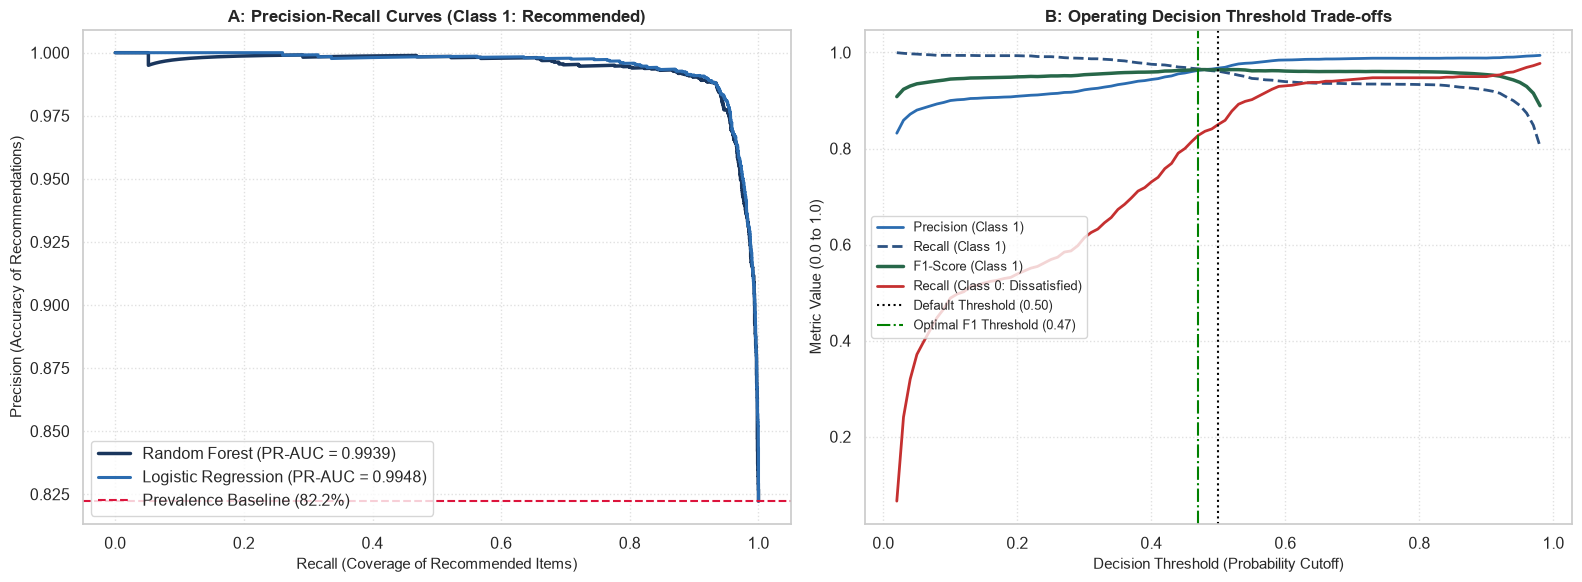

In [5]:
rf_probs = rf_model.predict_proba(X_test_trans)[:, 1]
lr_probs = lr_model.predict_proba(X_test_trans)[:, 1]

precision_rf, recall_rf, _ = precision_recall_curve(y_test, rf_probs)
precision_lr, recall_lr, _ = precision_recall_curve(y_test, lr_probs)
baseline_pr = np.mean(y_test)

thresholds = np.linspace(0.02, 0.98, 97)
thresh_records = []
for t in thresholds:
    p_pred = (rf_probs >= t).astype(int)
    p_prec = precision_score(y_test, p_pred, pos_label=1, zero_division=0)
    p_rec = recall_score(y_test, p_pred, pos_label=1, zero_division=0)
    p_f1 = f1_score(y_test, p_pred, pos_label=1, zero_division=0)
    p_rec0 = recall_score(y_test, p_pred, pos_label=0, zero_division=0)
    p_mcc = matthews_corrcoef(y_test, p_pred)
    
    thresh_records.append({
        'Threshold': round(t, 2),
        'Precision_Class1': round(p_prec, 4),
        'Recall_Class1': round(p_rec, 4),
        'F1_Class1': round(p_f1, 4),
        'Recall_Class0_Dissatisfied': round(p_rec0, 4),
        'MCC': round(p_mcc, 4)
    })
df_thresh = pd.DataFrame(thresh_records)
df_thresh.to_csv("threshold_optimization_schedule.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(recall_rf, precision_rf, color='#1A365D', linewidth=2.5, label=f"Random Forest (PR-AUC = {average_precision_score(y_test, rf_probs):.4f})")
axes[0].plot(recall_lr, precision_lr, color='#2B6CB0', linewidth=2.2, label=f"Logistic Regression (PR-AUC = {average_precision_score(y_test, lr_probs):.4f})")
axes[0].axhline(baseline_pr, color='crimson', linestyle='--', linewidth=1.5, label=f"Prevalence Baseline ({baseline_pr*100:.1f}%)")
axes[0].set_title("A: Precision-Recall Curves (Class 1: Recommended)", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Recall (Coverage of Recommended Items)", fontsize=11)
axes[0].set_ylabel("Precision (Accuracy of Recommendations)", fontsize=11)
axes[0].legend(loc='lower left', frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(df_thresh['Threshold'], df_thresh['Precision_Class1'], color='#2B6CB0', linewidth=2, label="Precision (Class 1)")
axes[1].plot(df_thresh['Threshold'], df_thresh['Recall_Class1'], color='#2C5282', linestyle='--', linewidth=2, label="Recall (Class 1)")
axes[1].plot(df_thresh['Threshold'], df_thresh['F1_Class1'], color='#276749', linewidth=2.5, label="F1-Score (Class 1)")
axes[1].plot(df_thresh['Threshold'], df_thresh['Recall_Class0_Dissatisfied'], color='#C53030', linewidth=2, label="Recall (Class 0: Dissatisfied)")
axes[1].axvline(0.50, color='black', linestyle=':', label="Default Threshold (0.50)")

opt_thresh_idx = df_thresh['F1_Class1'].idxmax()
opt_t = df_thresh.loc[opt_thresh_idx, 'Threshold']
axes[1].axvline(opt_t, color='green', linestyle='-.', label=f"Optimal F1 Threshold ({opt_t})")

axes[1].set_title("B: Operating Decision Threshold Trade-offs", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Decision Threshold (Probability Cutoff)", fontsize=11)
axes[1].set_ylabel("Metric Value (0.0 to 1.0)", fontsize=11)
axes[1].legend(loc='center left', frameon=True, fontsize=9.5)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("precision_recall_curves_and_threshold_tradeoffs.png", dpi=300)
plt.show()

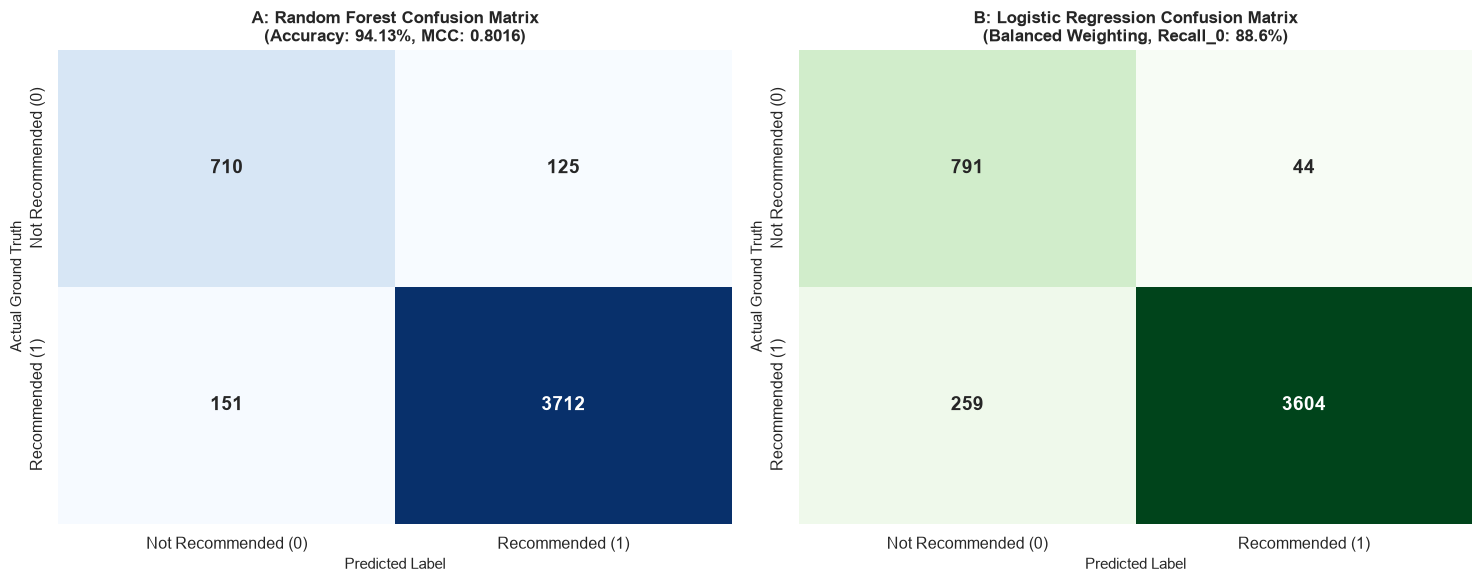

In [6]:
cm_rf = confusion_matrix(y_test, rf_model.predict(X_test_trans))
cm_lr = confusion_matrix(y_test, lr_model.predict(X_test_trans))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Not Recommended (0)', 'Recommended (1)'],
            yticklabels=['Not Recommended (0)', 'Recommended (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title("A: Random Forest Confusion Matrix\n(Accuracy: 94.13%, MCC: 0.8016)", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Predicted Label", fontsize=11)
axes[0].set_ylabel("Actual Ground Truth", fontsize=11)

sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['Not Recommended (0)', 'Recommended (1)'],
            yticklabels=['Not Recommended (0)', 'Recommended (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title("B: Logistic Regression Confusion Matrix\n(Balanced Weighting, Recall_0: 88.6%)", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Predicted Label", fontsize=11)
axes[1].set_ylabel("Actual Ground Truth", fontsize=11)

plt.tight_layout()
plt.savefig("confusion_matrices_comparison.png", dpi=300)
plt.show()

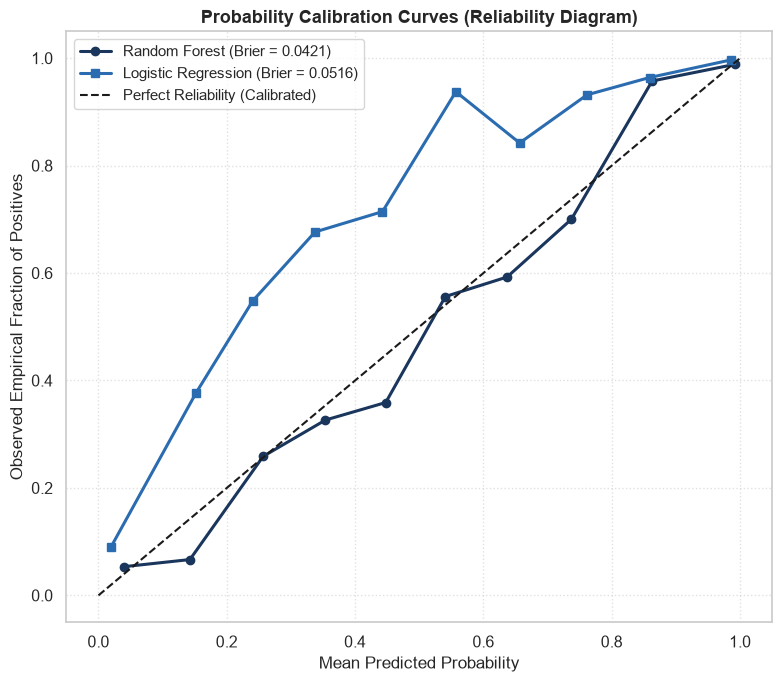

In [7]:
prob_true_rf, prob_pred_rf = calibration_curve(y_test, rf_probs, n_bins=10)
prob_true_lr, prob_pred_lr = calibration_curve(y_test, lr_probs, n_bins=10)

plt.figure(figsize=(8, 7))
plt.plot(prob_pred_rf, prob_true_rf, marker='o', linewidth=2.2, color='#1A365D', label=f"Random Forest (Brier = {brier_score_loss(y_test, rf_probs):.4f})")
plt.plot(prob_pred_lr, prob_true_lr, marker='s', linewidth=2.2, color='#2B6CB0', label=f"Logistic Regression (Brier = {brier_score_loss(y_test, lr_probs):.4f})")
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label="Perfect Reliability (Calibrated)")
plt.xlabel("Mean Predicted Probability", fontsize=12)
plt.ylabel("Observed Empirical Fraction of Positives", fontsize=12)
plt.title("Probability Calibration Curves (Reliability Diagram)", fontweight='bold', fontsize=13)
plt.legend(loc="upper left", frameon=True, fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig("probability_calibration_curves.png", dpi=300)
plt.show()